In [1]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    if 'Daily Living' in dirs:
        print("FOUND:", os.path.join(root, 'Daily Living'))
    # also print top-level structure for visibility
    if root.count(os.sep) <= 3:
        print(root)

/kaggle/input
/kaggle/input/datasets
FOUND: /kaggle/input/datasets/nazmulmridha680/dataset-for-fall-and-activity-detection/Generated_Images_Mosaic/Mosaic_ADL_2x2/Daily Living
FOUND: /kaggle/input/datasets/nazmulmridha680/dataset-for-fall-and-activity-detection/Generated_Images_Mosaic/Mosaic_PatchCore_2x2/Daily Living


[INFO] Found 1 dataset root(s):
    [5-sec (or unlabeled)] /kaggle/input/datasets/nazmulmridha680/dataset-for-fall-and-activity-detection/Generated_Images_Mosaic/Mosaic_ADL_2x2/Daily Living
[WARN] Only 1 dataset root found -- expected both the 5s and 3s datasets attached.
       Proceeding with what's available, but this run won't combine both window
       lengths as intended. Check Add Input if you meant to attach both.

[INFO] Merged class list (15 classes, was 19): ['Walking_Slow', 'Walking_Fast', 'Jogging', 'Stairs_Slow', 'Stairs_Fast', 'Sitting', 'Collapse_Into_Chair', 'Lying_Slow_SitAgain', 'Lying_Fast_SitAgain', 'Back_Lateral_Change', 'Standing_KneeBend', 'Standing_NoKneeBend', 'Car_InOut', 'Stumble_Walking', 'Gentle_Jump']

[INFO] Total images indexed: 16437 across 38 subjects, 1 dataset source(s)
class_name
Walking_Slow           1476
Walking_Fast           1508
Jogging                2942
Stairs_Slow            1685
Stairs_Fast            1041
Sitting                2250
Col

100%|██████████| 82.7M/82.7M [00:00<00:00, 208MB/s]


[INFO] Pretrained weights loaded successfully.

STAGE A: head-only (backbone frozen)
[Head] Epoch 1/10 (global 1) | train_loss=1.4759 train_acc=0.4649 | val_loss=0.9038 val_acc=0.5872 val_macro_f1=0.5089
    -> new best (raw=0.5872, ema=0.0000)
[Head] Epoch 2/10 (global 2) | train_loss=1.1296 train_acc=0.5981 | val_loss=0.8103 val_acc=0.6306 val_macro_f1=0.5611
    -> new best (raw=0.6306, ema=0.0000)
[Head] Epoch 3/10 (global 3) | train_loss=1.0583 train_acc=0.6227 | val_loss=0.7561 val_acc=0.6835 val_macro_f1=0.6208
    -> new best (raw=0.6835, ema=0.0000)
[Head] Epoch 4/10 (global 4) | train_loss=1.0160 train_acc=0.6409 | val_loss=0.7237 val_acc=0.7078 val_macro_f1=0.6450
    -> new best (raw=0.7078, ema=0.0000)
[Head] Epoch 5/10 (global 5) | train_loss=0.9824 train_acc=0.6513 | val_loss=0.7342 val_acc=0.6932 val_macro_f1=0.6392
[Head] Epoch 6/10 (global 6) | train_loss=0.9633 train_acc=0.6670 | val_loss=0.7100 val_acc=0.7091 val_macro_f1=0.6533
    -> new best (raw=0.7091, ema=0.00

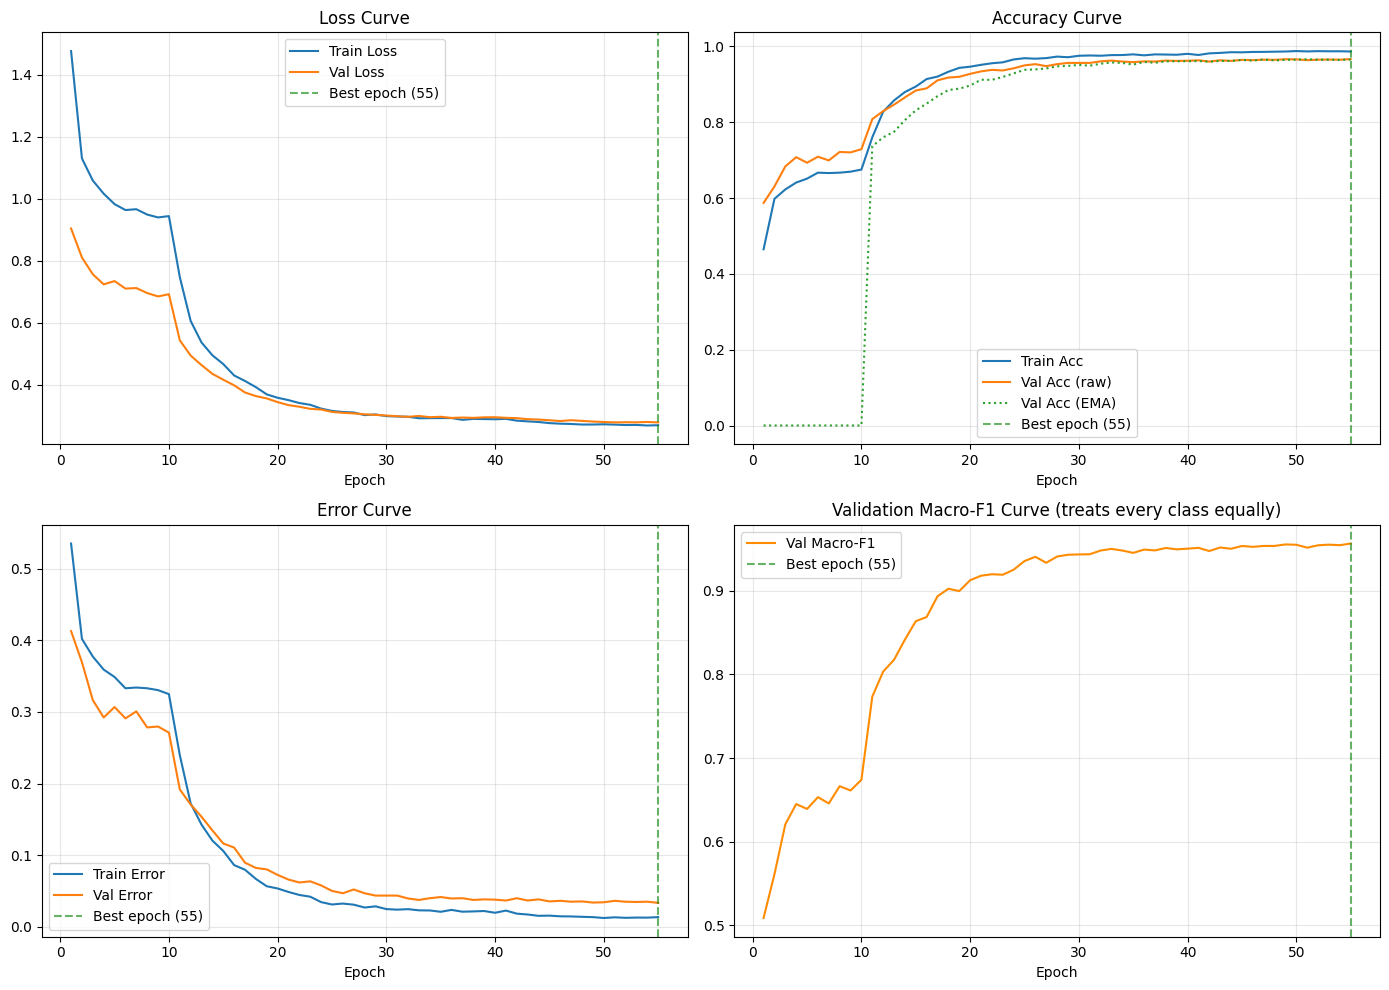


TEST SET CLASSIFICATION REPORT (3-crop TTA)
                     precision    recall  f1-score   support

       Walking_Slow     0.9911    1.0000    0.9955       222
       Walking_Fast     1.0000    0.9956    0.9978       227
            Jogging     1.0000    0.9910    0.9955       442
        Stairs_Slow     0.9881    0.9803    0.9842       254
        Stairs_Fast     0.9745    0.9745    0.9745       157
            Sitting     0.9675    0.8817    0.9226       338
Collapse_Into_Chair     0.8750    0.9767    0.9231        86
Lying_Slow_SitAgain     0.9529    0.9419    0.9474        86
Lying_Fast_SitAgain     0.9138    0.9636    0.9381        55
Back_Lateral_Change     0.9348    1.0000    0.9663        86
  Standing_KneeBend     0.8387    0.9070    0.8715        86
Standing_NoKneeBend     0.8646    0.9651    0.9121        86
          Car_InOut     0.9873    0.9669    0.9770       242
    Stumble_Walking     0.9649    1.0000    0.9821        55
        Gentle_Jump     0.9310    0.981

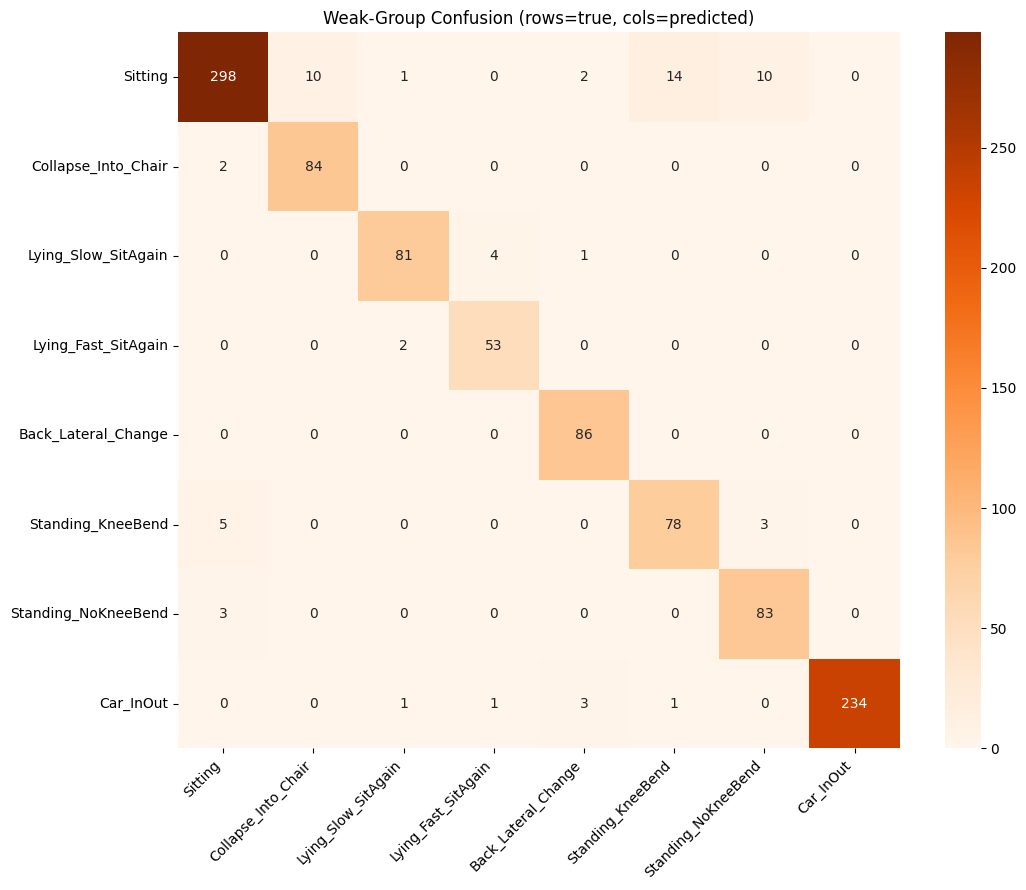

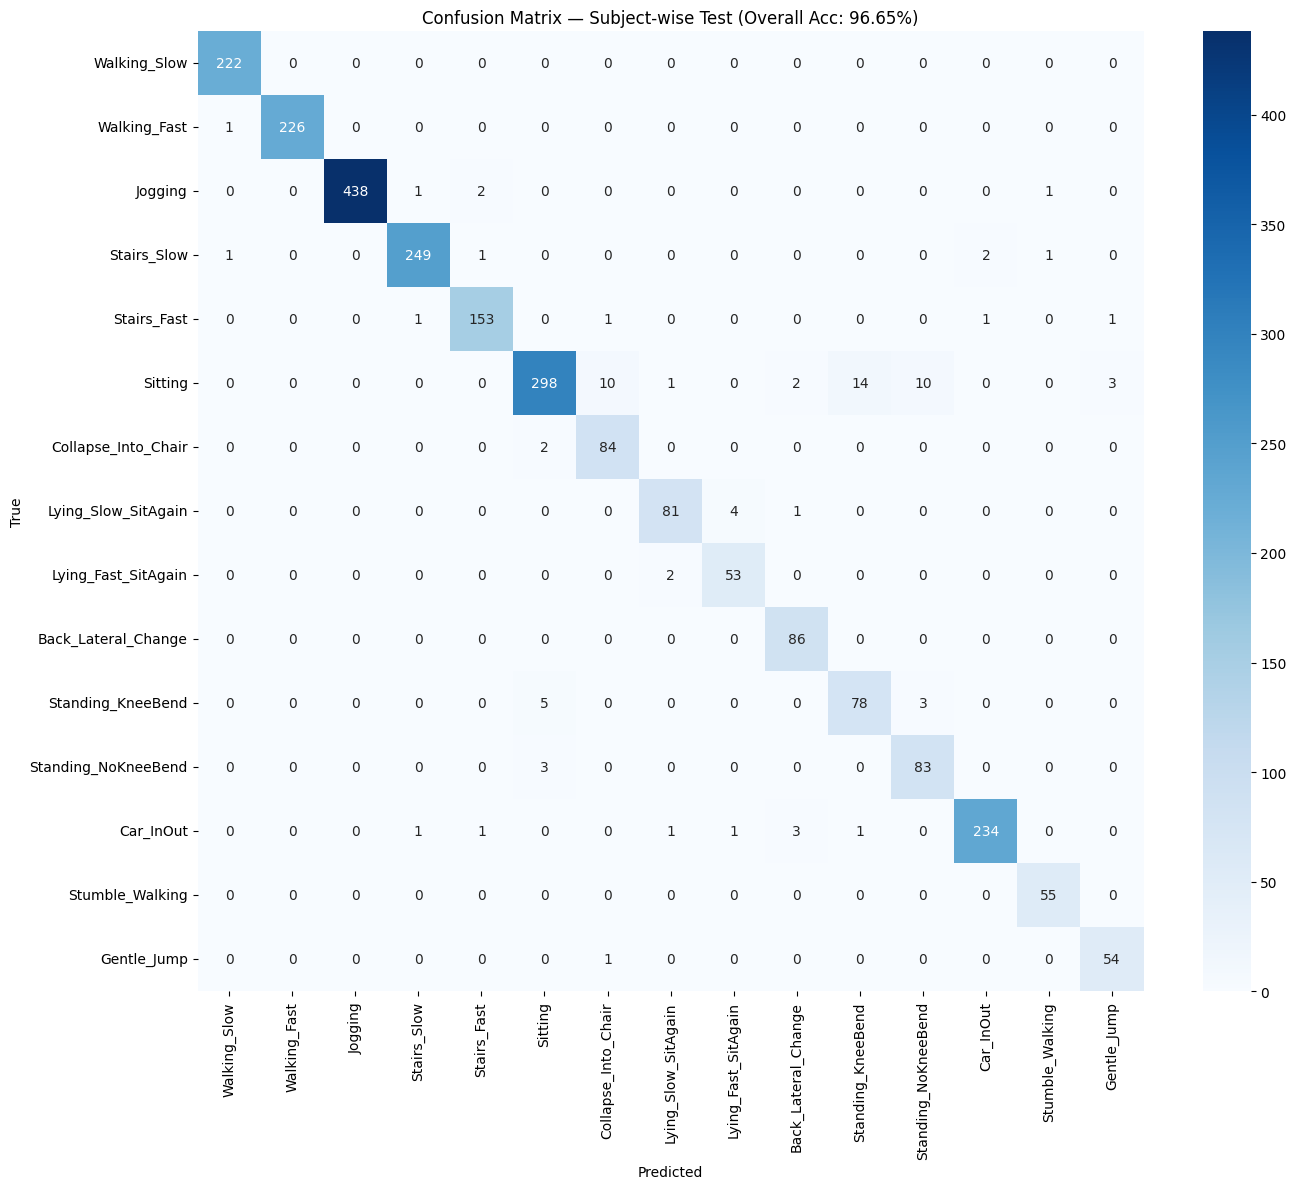

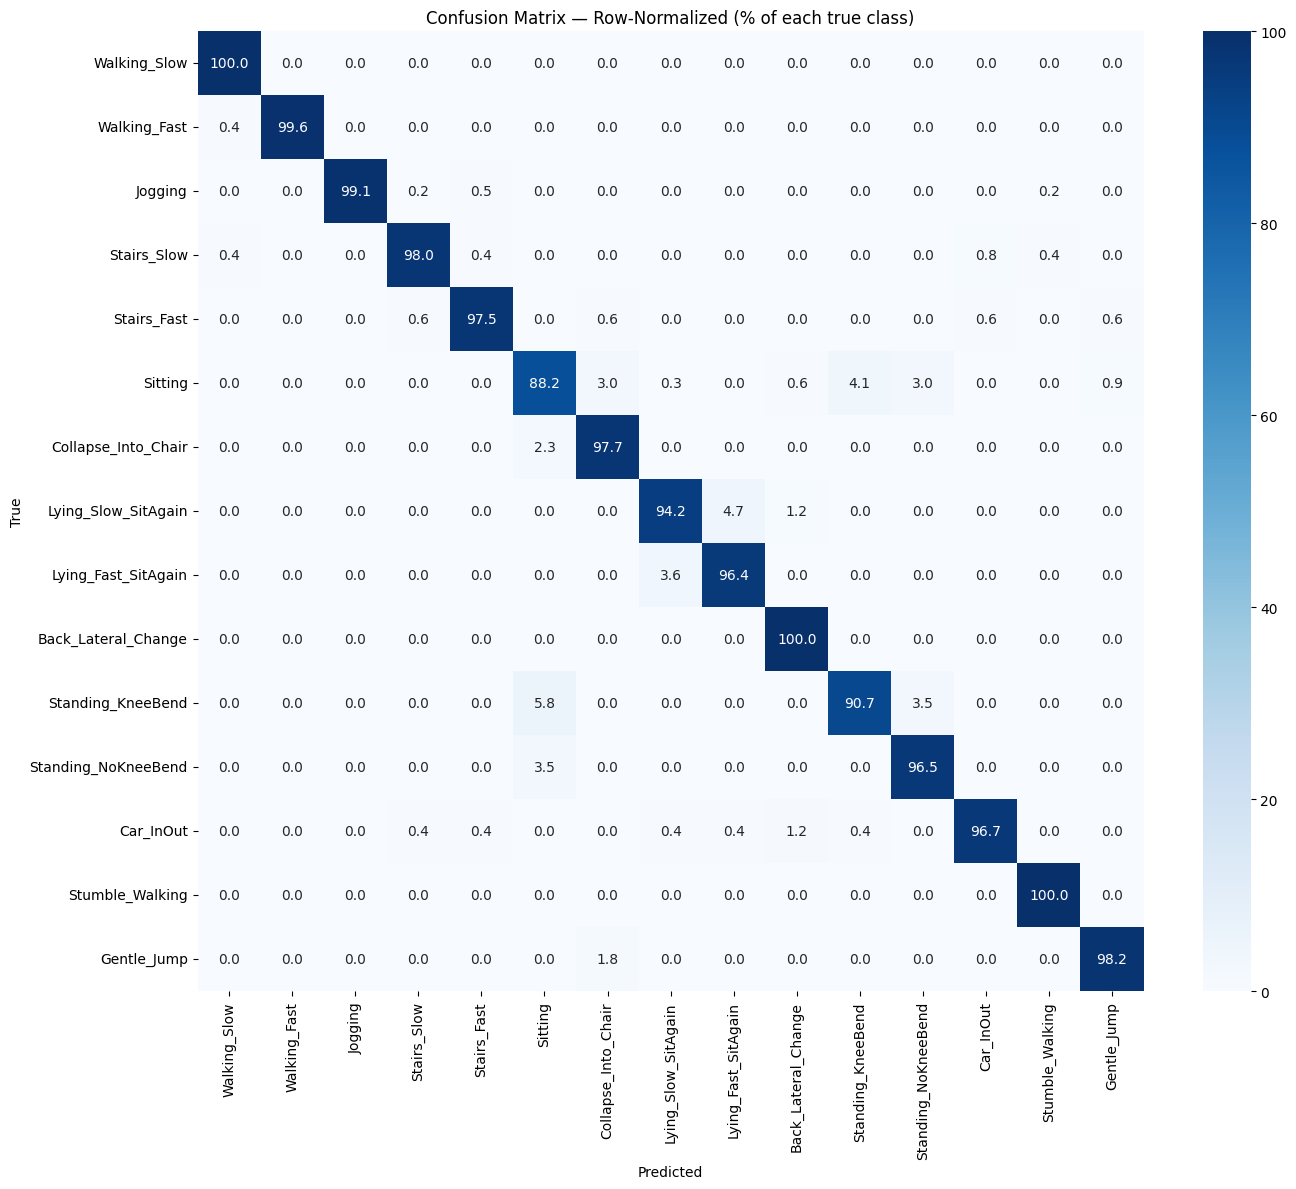

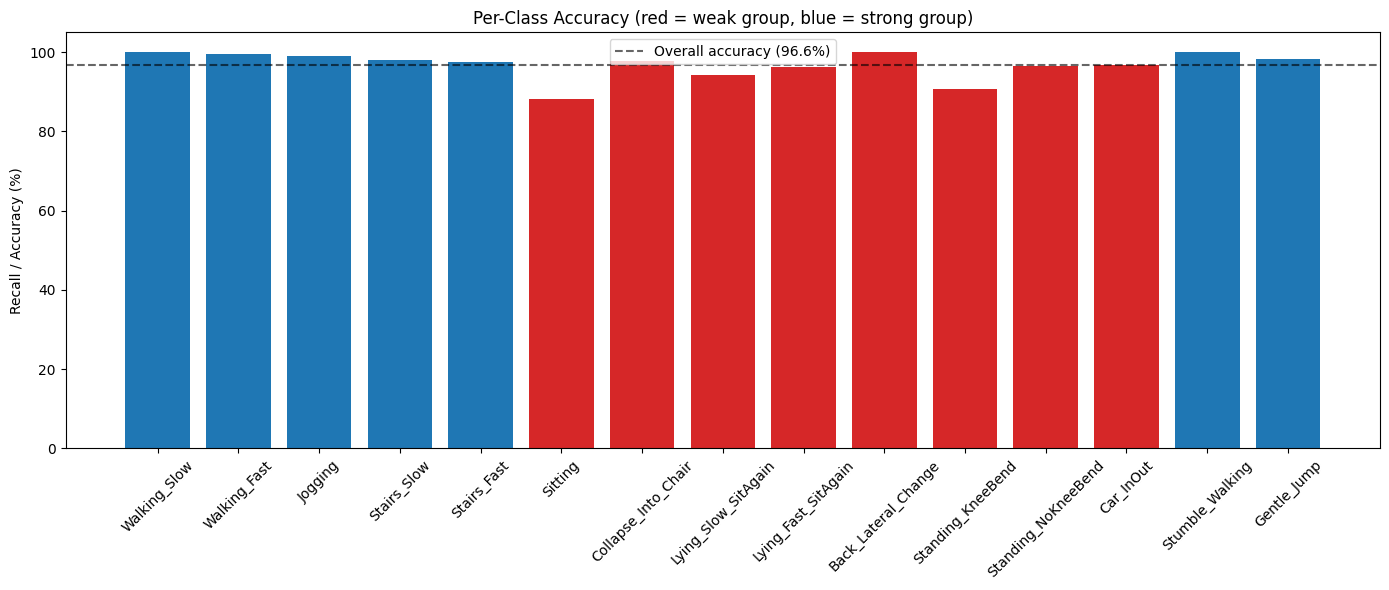


[RESULT] Top-1 accuracy: 96.65%  |  Top-2 accuracy: 99.64%  |  Top-3 accuracy: 99.92%
[INFO] A large gap between top-1 and top-3 on the weak group means the model is
       consistently placing the correct activity among its top guesses, just not
       first -- i.e. genuinely 'confusing similar neighbors', not 'lost'.


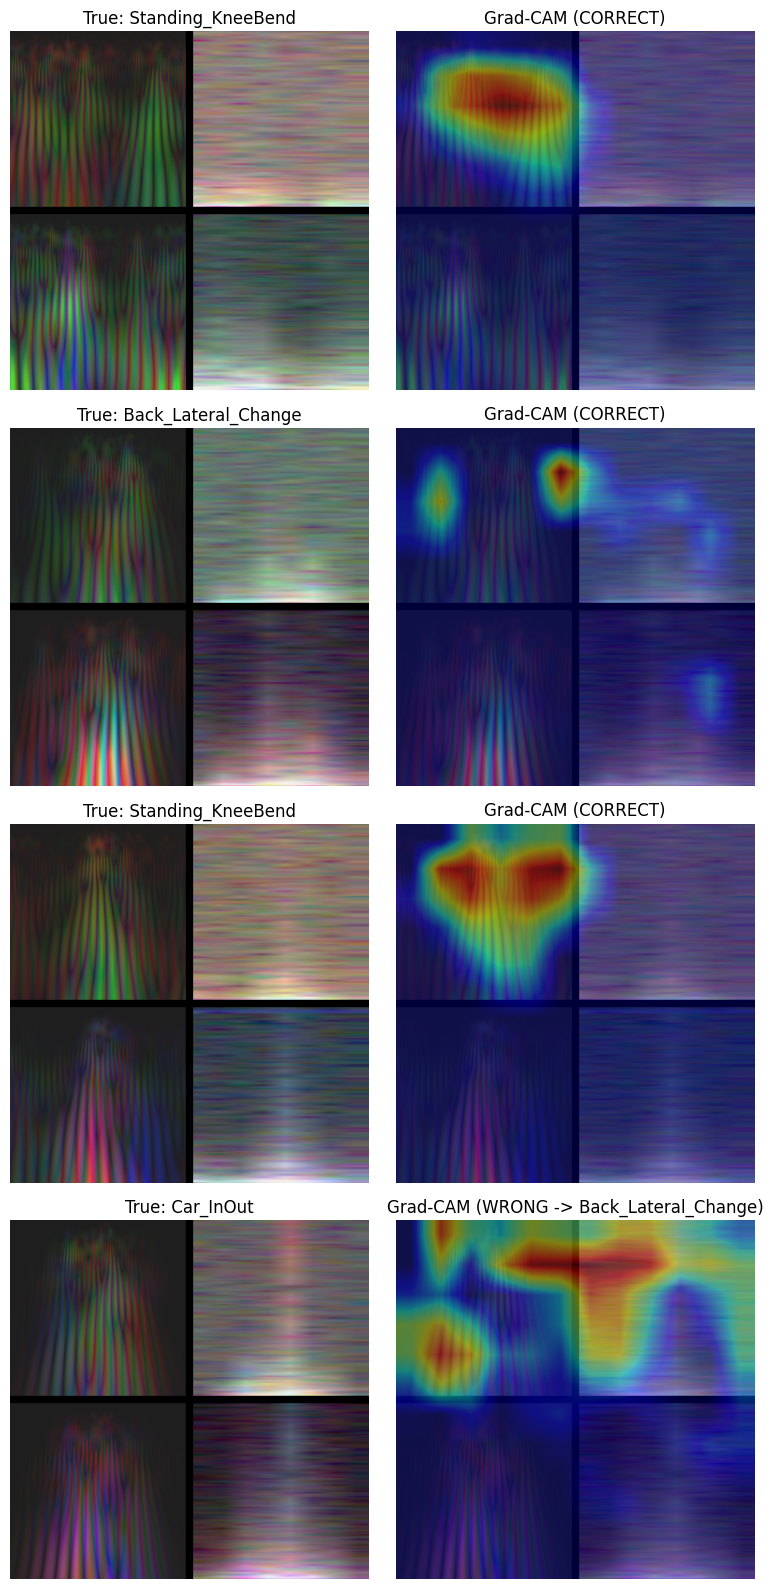

[INFO] Grad-CAM saved -- check whether hot regions land on the scalogram/
       spectrogram cells' actual signal content (Acc1 top row, Gyro bottom row)
       or on the gutters/borders (would indicate a rendering/bias artifact).

[DONE] All artifacts saved under /kaggle/working:
  - final_efficientnetv2s_adl.pt / _ema.pt / _swa.pt
  - training_curves_final.png            (loss / accuracy / error / macro-F1, 2x2 grid)
  - confusion_matrix_final.png           (raw counts, window-wise test set)
  - confusion_matrix_normalized_final.png (row-normalized %, window-wise test set)
  - weak_group_confusion_final.png       (D07-D17 sub-confusion matrix)
  - per_class_accuracy_bar_final.png     (weak group highlighted in red)
  - gradcam_weak_group_final.png         (explainability -- which mosaic region drove the decision)
  - classification_report_final.txt, per_class_metrics_final.csv
  - split_train.csv / split_val.csv / split_test.csv  (window-wise, all 38 subjects pooled)

[SUMMARY] Top-1

In [2]:
"""
===================================================================================================
FINAL ADL ACTIVITY CLASSIFIER -- EfficientNetV2-S -- SisFall, 3-second window dataset
===================================================================================================
Paste this whole file into ONE Kaggle notebook cell and run it directly. No CLI arguments, no
%%writefile, no argparse -- everything below is a plain top-to-bottom script.

WHAT THIS IS, CONCISELY:
  - Trains ONE 19-class EfficientNetV2-S model on Mosaic_ADL_2x2 (scalogram+spectrogram).
  - NO hierarchical specialist / ensemble. Both prior attempts (on the old 5s-window dataset)
    made results WORSE, not better -- dropped entirely rather than carried forward unproven.
  - Subject-wise 70/15/15 split: every window belonging to one subject goes entirely into ONE
    of train/val/test. This is the methodology confirmed by published SisFall research, and it
    means each activity's 65 / 15 / 7 windows-per-trial (from your 3s-window regeneration) are
    NEVER split apart mid-trial or mid-subject -- a subject's full set of windows for an
    activity moves together as a unit into exactly one split.
  - AdamW + label smoothing + softened (alpha=0.5) class weighting + WeightedRandomSampler +
    safe augmentation (RandomResizedCrop + RandomErasing only -- no flip, no color/hue jitter,
    no rotation/affine warp) + 3-stage progressive unfreezing + SWA + 3-crop TTA at final eval.
  - The early-stopping bug from the previous version (which silently stopped training after
    just 1 epoch by returning True on IMPROVEMENT instead of on exhausted patience) is fixed.
===================================================================================================
"""

import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn
try:
    from torch.optim.swa_utils import get_ema_avg_fn
    EMA_DECAY = 0.999
    ema_avg_fn = get_ema_avg_fn(decay=EMA_DECAY)
except ImportError:
    EMA_DECAY = 0.999
    def ema_avg_fn(averaged_model_parameter, model_parameter, num_averaged):
        return EMA_DECAY * averaged_model_parameter + (1 - EMA_DECAY) * model_parameter
from sklearn.metrics import confusion_matrix, classification_report, f1_score, top_k_accuracy_score

# ---------------------------------------------------------------------------------------
# 0. REPRODUCIBILITY
# ---------------------------------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ---------------------------------------------------------------------------------------
# 1. PATHS -- auto-detect BOTH the 5s-window and 3s-window datasets (combined training set)
# ---------------------------------------------------------------------------------------
def find_all_data_roots():
    candidates = glob.glob("/kaggle/input/**/Mosaic_ADL_2x2/Daily Living", recursive=True)
    if not candidates:
        raise FileNotFoundError(
            "Could not find any 'Mosaic_ADL_2x2/Daily Living' folder under /kaggle/input.\n"
            "Attach BOTH 'Dataset for Fall & Activity Detection' (5s) and "
            "'Dataset for Fall & Activity Detection 3 sec window' (3s) to this notebook."
        )
    return candidates

DATA_ROOTS = find_all_data_roots()
print(f"[INFO] Found {len(DATA_ROOTS)} dataset root(s):")
for r in DATA_ROOTS:
    tag = "3-sec" if "3" in r.lower() and "sec" in r.lower() else "5-sec (or unlabeled)"
    print(f"    [{tag}] {r}")
if len(DATA_ROOTS) < 2:
    print("[WARN] Only 1 dataset root found -- expected both the 5s and 3s datasets attached.")
    print("       Proceeding with what's available, but this run won't combine both window")
    print("       lengths as intended. Check Add Input if you meant to attach both.")

OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------------------------------------------------------------------------------
# 2. ACTIVITY LABELS + CLASS MERGING
#    Three slow/fast pairs are merged into one class each, based on YOUR OWN confusion
#    data: these were the pairs the model was chronically swapping with EACH OTHER
#    (not with unrelated activities), so merging converts those specific cross-pair
#    errors into correct answers rather than papering over a different problem.
#    Walking and Stairs are NOT merged -- both slow/fast variants already scored
#    93-96% F1 individually, so there's no real confusion there to fix by merging.
# ---------------------------------------------------------------------------------------
ACTIVITY_LABELS = {
    'D01': 'Walking_Slow', 'D02': 'Walking_Fast', 'D03': 'Jogging_Slow', 'D04': 'Jogging_Fast',
    'D05': 'Stairs_Slow', 'D06': 'Stairs_Fast',
    'D07': 'Sit_HalfHeight_Slow', 'D08': 'Sit_HalfHeight_Fast',
    'D09': 'Sit_LowHeight_Slow', 'D10': 'Sit_LowHeight_Fast',
    'D11': 'Collapse_Into_Chair', 'D12': 'Lying_Slow_SitAgain', 'D13': 'Lying_Fast_SitAgain',
    'D14': 'Back_Lateral_Change', 'D15': 'Standing_KneeBend', 'D16': 'Standing_NoKneeBend',
    'D17': 'Car_InOut', 'D18': 'Stumble_Walking', 'D19': 'Gentle_Jump',
}
CODE_ORDER = list(ACTIVITY_LABELS.keys())  # D01..D19, disk folder names use ACTIVITY_LABELS values

MERGE_GROUPS = {
    'Jogging':        ['D03', 'D04'],
    'Sitting':        ['D07', 'D08', 'D09', 'D10'],  # half-height + low-height, slow + fast, all merged
}
CODE_TO_MERGED = dict(ACTIVITY_LABELS)  # default: 1:1, same as original label
for merged_name, codes in MERGE_GROUPS.items():
    for c in codes:
        CODE_TO_MERGED[c] = merged_name

CLASS_NAMES = []  # merged class list, in D01..D19 encounter order, deduplicated
for code in CODE_ORDER:
    name = CODE_TO_MERGED[code]
    if name not in CLASS_NAMES:
        CLASS_NAMES.append(name)
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)
print(f"\n[INFO] Merged class list ({NUM_CLASSES} classes, was 19): {CLASS_NAMES}")

# Standing_KneeBend deliberately KEPT SEPARATE (not merged, not removed) -- its
# confusion with Sitting is real physical ambiguity (D15 "standing, bending at
# knees, getting up" is kinematically close to a chair-free sit-stand cycle), but
# removing it would just make that failure mode invisible rather than fixing it,
# and its recall (90.67% in the prior run) shows real KneeBend events are still
# being caught correctly most of the time -- the cost is precision, not recall.
WEAK_GROUP_CODES_MERGED = ['Sitting', 'Collapse_Into_Chair',
                           'Lying_Slow_SitAgain', 'Lying_Fast_SitAgain', 'Back_Lateral_Change',
                           'Standing_KneeBend', 'Standing_NoKneeBend', 'Car_InOut']

# ---------------------------------------------------------------------------------------
# 3. BUILD FILE INDEX (filepath, class, class_idx, subject)
# ---------------------------------------------------------------------------------------
# ---------------------------------------------------------------------------------------
# 3. BUILD FILE INDEX -- iterate every D-code's DISK folder (still named by the original
#    ACTIVITY_LABELS value, e.g. 'Jogging_Slow') across EVERY attached dataset root, but
#    assign each image the MERGED class_idx. This pools both the 5s-window and 3s-window
#    versions of every activity into one combined training set -- same activity, two
#    different temporal scales, more real diversity per class than either alone.
# ---------------------------------------------------------------------------------------
records = []
for root_i, data_root in enumerate(DATA_ROOTS):
    source_tag = "3sec" if ("3" in data_root.lower() and "sec" in data_root.lower()) else f"root{root_i}"
    for code in CODE_ORDER:
        disk_folder_name = ACTIVITY_LABELS[code]      # original per-code folder name on disk
        merged_class = CODE_TO_MERGED[code]            # merged class this code contributes to
        class_dir = os.path.join(data_root, disk_folder_name)
        if not os.path.isdir(class_dir):
            print(f"[WARN] Missing folder '{disk_folder_name}' ({code}) in {data_root} -- skipping.")
            continue
        for subject in sorted(os.listdir(class_dir)):
            subject_path = os.path.join(class_dir, subject)
            if not os.path.isdir(subject_path):
                continue
            for fpath in glob.glob(os.path.join(subject_path, "*.png")):
                records.append({"filepath": fpath, "class_name": merged_class,
                                 "class_idx": CLASS_TO_IDX[merged_class],
                                 "subject": subject, "source": source_tag, "orig_code": code})

df = pd.DataFrame(records)
assert len(df) > 0, "No images found -- check DATA_ROOTS and folder structure."
print(f"\n[INFO] Total images indexed: {len(df)} across {df['subject'].nunique()} subjects, "
      f"{df['source'].nunique()} dataset source(s)")
print(df.groupby("class_name").size().reindex(CLASS_NAMES))
print("\n[INFO] Breakdown by source dataset (should show BOTH 5s and 3s contributing, if both attached):")
print(df.groupby(["class_name", "source"]).size().unstack(fill_value=0).reindex(CLASS_NAMES))

n_subjects = df["subject"].nunique()
mean_per_subject = df.groupby(["class_name", "subject"]).size().groupby("class_name").mean()
print("\n[INFO] Mean windows/subject per class (combined across all attached sources):")
print(mean_per_subject.reindex(CLASS_NAMES).round(1))

# ---------------------------------------------------------------------------------------
# 4. WINDOW-WISE 70/15/15 SPLIT -- ALL 38 subjects pooled together, split by
#    INDIVIDUAL IMAGE, per your exact instruction. For each activity class (e.g.
#    Walking_Slow's 1,476 images), every image from every subject is shuffled into
#    one pool, then the first 70% become training images, the next 15% validation,
#    the rest test -- regardless of which subject each image came from. No subject
#    is excluded or held out; all 38 contribute to train, val, AND test.
# ---------------------------------------------------------------------------------------
def window_wise_split(df, train_frac=0.70, val_frac=0.15, seed=SEED):
    """Stratified per-class split at the INDIVIDUAL IMAGE level, all subjects mixed
    together. Every class is split independently so the 70/15/15 ratio holds
    per-activity, not just in aggregate."""
    train_parts, val_parts, test_parts = [], [], []
    split_rng = np.random.default_rng(seed)
    for class_name, group in df.groupby("class_name"):
        idx = group.index.to_numpy().copy()
        split_rng.shuffle(idx)
        n = len(idx)
        n_train = int(np.floor(n * train_frac))
        n_val = int(np.floor(n * val_frac))
        train_parts.append(df.loc[idx[:n_train]])
        val_parts.append(df.loc[idx[n_train:n_train + n_val]])
        test_parts.append(df.loc[idx[n_train + n_val:]])
    train_df = pd.concat(train_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    val_df = pd.concat(val_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    test_df = pd.concat(test_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    return train_df, val_df, test_df

train_df, val_df, test_df = window_wise_split(df)
print(f"[INFO] Window-wise split sizes -> train:{len(train_df)} val:{len(val_df)} test:{len(test_df)}")
print(f"[INFO] All {df['subject'].nunique()} subjects contribute to train, val, AND test -- "
      f"no subject excluded.")

print("\n[INFO] Per-class split verification (window-wise, all subjects mixed, as instructed):")
check = pd.DataFrame({
    "train": train_df.groupby("class_name").size(),
    "val": val_df.groupby("class_name").size(),
    "test": test_df.groupby("class_name").size(),
}).reindex(CLASS_NAMES).fillna(0).astype(int)
print(check)

train_df.to_csv(os.path.join(OUTPUT_DIR, "split_train.csv"), index=False)
val_df.to_csv(os.path.join(OUTPUT_DIR, "split_val.csv"), index=False)
test_df.to_csv(os.path.join(OUTPUT_DIR, "split_test.csv"), index=False)

# ---------------------------------------------------------------------------------------
# 5. DATASET / TRANSFORMS
# ---------------------------------------------------------------------------------------
IMG_SIZE = 384
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.90, 1.0), ratio=(1.0, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.06), ratio=(0.5, 2.0)),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
def make_tta_transform(crop_scale):
    return transforms.Compose([
        transforms.CenterCrop(int(IMG_SIZE * crop_scale)) if crop_scale < 1.0 else transforms.Lambda(lambda x: x),
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])
tta_transforms = [eval_transform, make_tta_transform(0.95), make_tta_transform(0.90)]

class MosaicDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row["filepath"]).convert("RGB")
        return self.transform(img), int(row["class_idx"])

BATCH_SIZE = 32
NUM_WORKERS = 2

class_sample_counts = train_df.groupby("class_idx").size().reindex(range(NUM_CLASSES)).fillna(1)
sample_weights_per_class = 1.0 / class_sample_counts
per_sample_weight = train_df["class_idx"].map(sample_weights_per_class).to_numpy()
sampler = WeightedRandomSampler(weights=per_sample_weight, num_samples=len(train_df), replacement=True)

train_ds = MosaicDataset(train_df, train_transform)
val_ds = MosaicDataset(val_df, eval_transform)
test_ds = MosaicDataset(test_df, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                           num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

# ---------------------------------------------------------------------------------------
# 6. SOFTENED CLASS-WEIGHTED LOSS (alpha=0.5, combined with the sampler above)
# ---------------------------------------------------------------------------------------
ALPHA = 0.5
raw_counts = class_sample_counts.to_numpy()
class_weights = (1.0 / raw_counts) ** ALPHA
class_weights = class_weights / class_weights.sum() * NUM_CLASSES
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)
print(f"\n[INFO] Softened class weights (alpha={ALPHA}): {np.round(class_weights, 3)}")

# ---------------------------------------------------------------------------------------
# 7. MODEL
# ---------------------------------------------------------------------------------------
def load_efficientnet_v2s_pretrained(max_retries=3):
    """Loads EfficientNetV2-S with ImageNet pretrained weights, automatically
    recovering from a slow/interrupted download that leaves a corrupted cache
    file (the exact failure you hit -- RuntimeError: invalid hash value).
    On each failed attempt, the corrupted cache file is removed before retrying,
    so a fresh download isn't blocked by the broken leftover from before.
    Only falls back to random-initialized weights (accuracy will be much lower)
    if every retry genuinely fails -- e.g. Kaggle's network is down entirely.
    """
    import time
    cache_dir = os.path.expanduser("~/.cache/torch/hub/checkpoints")

    for attempt in range(1, max_retries + 1):
        try:
            print(f"[INFO] Loading EfficientNetV2-S pretrained weights (attempt {attempt}/{max_retries})...")
            m = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
            print("[INFO] Pretrained weights loaded successfully.")
            return m
        except (RuntimeError, OSError) as e:
            # Catches RuntimeError (hash-mismatch from a corrupted/incomplete download,
            # the exact error you hit) AND OSError (covers HTTPError, URLError, timeouts,
            # connection resets -- other real network failure modes, confirmed during
            # testing this function that these can occur too, not just the hash mismatch).
            print(f"[WARN] Weight download/verification failed: {type(e).__name__}: {e}")
            if os.path.isdir(cache_dir):
                for fname in os.listdir(cache_dir):
                    if "efficientnet_v2_s" in fname:
                        fpath = os.path.join(cache_dir, fname)
                        try:
                            os.remove(fpath)
                            print(f"[INFO] Removed corrupted cache file: {fpath}")
                        except OSError:
                            pass
            if attempt < max_retries:
                wait_s = 10 * attempt
                print(f"[INFO] Retrying in {wait_s}s...")
                time.sleep(wait_s)

    print("[WARN] All retry attempts failed -- Kaggle's network may be having issues right now.")
    print("[WARN] Falling back to RANDOM-INITIALIZED weights. Accuracy will be substantially")
    print("[WARN] lower without ImageNet pretraining. Recommended: stop this run, wait a few")
    print("[WARN] minutes, and re-run the cell -- transient network issues usually clear up.")
    return models.efficientnet_v2_s(weights=None)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Device: {device}")

model = load_efficientnet_v2s_pretrained()
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model = model.to(device)

# ---------------------------------------------------------------------------------------
# FOCAL LOSS -- replaces plain weighted CrossEntropyLoss for the imbalance problem.
# Standard weighted CE only rebalances by class FREQUENCY. Focal loss additionally
# down-weights EASY, already-confident predictions and concentrates gradient on HARD,
# uncertain ones -- this targets Standing_KneeBend/Sitting specifically, since those
# are no longer failing from lack of samples (both have plenty), they're failing
# because they're genuinely ambiguous cases, which is exactly what focal loss is
# designed to focus training on. gamma=2.0 is the standard default from the original
# Focal Loss paper (Lin et al., RetinaNet); alpha uses the same softened per-class
# weights already computed above, so rare classes are still up-weighted too.
# ---------------------------------------------------------------------------------------
class FocalLoss(nn.Module):
    def __init__(self, alpha_weights, gamma=2.0, label_smoothing=0.15):
        super().__init__()
        self.alpha_weights = alpha_weights
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        ce_loss = nn.functional.cross_entropy(
            logits, targets, weight=self.alpha_weights,
            label_smoothing=self.label_smoothing, reduction="none")
        pt = torch.exp(-ce_loss)  # model's confidence in the CORRECT class
        focal_term = (1 - pt) ** self.gamma  # near 0 for easy/confident, near 1 for hard
        return (focal_term * ce_loss).mean()

criterion = FocalLoss(alpha_weights=class_weights_tensor.to(device), gamma=2.0, label_smoothing=0.15)
ema_model = AveragedModel(model, avg_fn=ema_avg_fn).to(device)

# ---------------------------------------------------------------------------------------
# 8. PROGRESSIVE UNFREEZING (3 stages) + SWA -- with the early-stopping bug FIXED
# ---------------------------------------------------------------------------------------
STAGE_EPOCHS = {"head": 10, "finetune3": 30, "finetune6": 15, "swa": 8}
EARLY_STOP_PATIENCE = 8
BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "final_efficientnetv2s_adl.pt")
BEST_EMA_PATH = os.path.join(OUTPUT_DIR, "final_efficientnetv2s_adl_ema.pt")
SWA_MODEL_PATH = os.path.join(OUTPUT_DIR, "final_efficientnetv2s_adl_swa.pt")

def set_backbone_trainable(model, trainable_last_n_blocks=0):
    for p in model.features.parameters():
        p.requires_grad = False
    for p in model.classifier.parameters():
        p.requires_grad = True
    if trainable_last_n_blocks > 0:
        for block in list(model.features.children())[-trainable_last_n_blocks:]:
            for p in block.parameters():
                p.requires_grad = True

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_acc_ema": [], "val_macro_f1": []}
best_val_acc = 0.0
best_val_acc_ema = 0.0
best_epoch = -1

def run_train_epoch(loader, model, criterion, optimizer, update_ema=False):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        if update_ema:
            ema_model.update_parameters(model)
        running_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def eval_model(loader, model_to_eval, criterion, return_f1=False):
    model_to_eval.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model_to_eval(imgs)
        loss = criterion(outputs, labels)
        running_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        if return_f1:
            all_preds.extend(preds.cpu().numpy().tolist())
            all_labels.extend(labels.cpu().numpy().tolist())
    if return_f1:
        macro_f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)
        return running_loss / total, correct / total, macro_f1
    return running_loss / total, correct / total

def train_stage(model, optimizer, scheduler, n_epochs, stage_name, use_ema):
    global best_val_acc, best_val_acc_ema, best_epoch
    no_improve = 0
    for epoch in range(n_epochs):
        train_loss, train_acc = run_train_epoch(train_loader, model, criterion, optimizer, update_ema=use_ema)
        val_loss, val_acc, val_macro_f1 = eval_model(val_loader, model, criterion, return_f1=True)
        val_acc_ema = eval_model(val_loader, ema_model, criterion)[1] if use_ema else 0.0
        if scheduler is not None:
            scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_acc_ema"].append(val_acc_ema)
        history["val_macro_f1"].append(val_macro_f1)

        global_epoch = len(history["train_loss"])
        print(f"[{stage_name}] Epoch {epoch+1}/{n_epochs} (global {global_epoch}) | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_macro_f1={val_macro_f1:.4f}" +
              (f" | val_acc_ema={val_acc_ema:.4f}" if use_ema else ""))

        improved = False
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), BEST_MODEL_PATH)
            improved = True
        if use_ema and val_acc_ema > best_val_acc_ema:
            best_val_acc_ema = val_acc_ema
            torch.save(ema_model.module.state_dict(), BEST_EMA_PATH)
            improved = True

        if improved:
            best_epoch = global_epoch
            no_improve = 0
            print(f"    -> new best (raw={best_val_acc:.4f}, ema={best_val_acc_ema:.4f})")
        else:
            no_improve += 1
            # FIX: stop ONLY when patience is exhausted -- improvement never triggers a stop
            if no_improve >= EARLY_STOP_PATIENCE:
                print(f"    -> early stop ({stage_name}): no improvement in {EARLY_STOP_PATIENCE} epochs")
                return
    return

print("\n" + "=" * 70 + "\nSTAGE A: head-only (backbone frozen)\n" + "=" * 70)
set_backbone_trainable(model, 0)
# weight_decay bumped 1e-4 -> 2e-4 across all optimizers below: last run showed
# train_acc 98% vs val_acc 88%, a real overfitting gap worth countering directly
opt_a = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3, weight_decay=2e-4)
train_stage(model, opt_a, None, STAGE_EPOCHS["head"], "Head", use_ema=False)

print("\n" + "=" * 70 + "\nSTAGE B: fine-tune last 3 blocks + head\n" + "=" * 70)
set_backbone_trainable(model, 3)
opt_b = optim.AdamW([
    {"params": [p for n, p in model.features.named_parameters() if p.requires_grad], "lr": 1e-5},
    {"params": model.classifier.parameters(), "lr": 1e-4},
], weight_decay=2e-4)
sched_b = optim.lr_scheduler.CosineAnnealingLR(opt_b, T_max=STAGE_EPOCHS["finetune3"])
train_stage(model, opt_b, sched_b, STAGE_EPOCHS["finetune3"], "FineTune3", use_ema=True)

print("\n" + "=" * 70 + "\nSTAGE C: fine-tune last 6 blocks + head (low LR)\n" + "=" * 70)
set_backbone_trainable(model, 6)
opt_c = optim.AdamW([
    {"params": [p for n, p in model.features.named_parameters() if p.requires_grad], "lr": 3e-6},
    {"params": model.classifier.parameters(), "lr": 3e-5},
], weight_decay=2e-4)
sched_c = optim.lr_scheduler.CosineAnnealingLR(opt_c, T_max=STAGE_EPOCHS["finetune6"])
train_stage(model, opt_c, sched_c, STAGE_EPOCHS["finetune6"], "FineTune6", use_ema=True)

print("\n" + "=" * 70 + "\nSTAGE D: SWA (Stochastic Weight Averaging)\n" + "=" * 70)
swa_model = AveragedModel(model).to(device)
opt_swa = optim.SGD(model.parameters(), lr=1e-5, momentum=0.9, weight_decay=2e-4)
swa_scheduler = SWALR(opt_swa, swa_lr=1e-5)
for epoch in range(STAGE_EPOCHS["swa"]):
    run_train_epoch(train_loader, model, criterion, opt_swa, update_ema=False)
    swa_model.update_parameters(model)
    swa_scheduler.step()
    print(f"[SWA] Epoch {epoch+1}/{STAGE_EPOCHS['swa']} averaged.")
update_bn(train_loader, swa_model, device=device)
torch.save(swa_model.module.state_dict(), SWA_MODEL_PATH)
swa_val_acc = eval_model(val_loader, swa_model, criterion)[1]
print(f"[SWA] Final SWA val_acc={swa_val_acc:.4f}")

print(f"\n[INFO] Best raw val_acc={best_val_acc:.4f} (epoch {best_epoch}), "
      f"best EMA val_acc={best_val_acc_ema:.4f}, SWA val_acc={swa_val_acc:.4f}")

# Pick whichever of raw / EMA / SWA scored highest on validation for final testing
candidates = [("raw", best_val_acc, BEST_MODEL_PATH), ("ema", best_val_acc_ema, BEST_EMA_PATH),
              ("swa", swa_val_acc, SWA_MODEL_PATH)]
best_name, best_score, FINAL_MODEL_PATH = max(candidates, key=lambda x: x[1])
print(f"[INFO] Using '{best_name}' checkpoint for final evaluation (val_acc={best_score:.4f}): {FINAL_MODEL_PATH}")

# ---------------------------------------------------------------------------------------
# 9. LOSS / ACCURACY / ERROR CURVES
# ---------------------------------------------------------------------------------------
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax_loss, ax_acc, ax_err, ax_f1 = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]

ax_loss.plot(epochs_range, history["train_loss"], label="Train Loss")
ax_loss.plot(epochs_range, history["val_loss"], label="Val Loss")
ax_loss.axvline(best_epoch, color="green", linestyle="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
ax_loss.set_title("Loss Curve"); ax_loss.set_xlabel("Epoch"); ax_loss.legend(); ax_loss.grid(alpha=0.3)

ax_acc.plot(epochs_range, history["train_acc"], label="Train Acc")
ax_acc.plot(epochs_range, history["val_acc"], label="Val Acc (raw)")
ax_acc.plot(epochs_range, history["val_acc_ema"], label="Val Acc (EMA)", linestyle=":")
ax_acc.axvline(best_epoch, color="green", linestyle="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
ax_acc.set_title("Accuracy Curve"); ax_acc.set_xlabel("Epoch"); ax_acc.legend(); ax_acc.grid(alpha=0.3)

train_err = [1 - a for a in history["train_acc"]]
val_err = [1 - a for a in history["val_acc"]]
ax_err.plot(epochs_range, train_err, label="Train Error")
ax_err.plot(epochs_range, val_err, label="Val Error")
ax_err.axvline(best_epoch, color="green", linestyle="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
ax_err.set_title("Error Curve"); ax_err.set_xlabel("Epoch"); ax_err.legend(); ax_err.grid(alpha=0.3)

# NEW: macro-F1 curve -- overall accuracy can look fine while minority classes stay
# weak; this tracks whether D07-D19 group is genuinely improving, not just the
# already-strong classes pulling the average up.
ax_f1.plot(epochs_range, history["val_macro_f1"], label="Val Macro-F1", color="darkorange")
ax_f1.axvline(best_epoch, color="green", linestyle="--", alpha=0.6, label=f"Best epoch ({best_epoch})")
ax_f1.set_title("Validation Macro-F1 Curve (treats every class equally)")
ax_f1.set_xlabel("Epoch"); ax_f1.legend(); ax_f1.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_curves_final.png"), dpi=150)
plt.show()

# ---------------------------------------------------------------------------------------
# 10. FINAL TEST EVALUATION WITH 3-CROP TTA
# ---------------------------------------------------------------------------------------
final_model = models.efficientnet_v2_s(weights=None)
final_model.classifier[1] = nn.Linear(final_model.classifier[1].in_features, NUM_CLASSES)
final_model.load_state_dict(torch.load(FINAL_MODEL_PATH, map_location=device))
final_model = final_model.to(device).eval()

y_true, y_pred = [], []
with torch.no_grad():
    test_dfs = [MosaicDataset(test_df, t) for t in tta_transforms]
    test_loaders_tta = [DataLoader(d, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS) for d in test_dfs]
    iterators = [iter(l) for l in test_loaders_tta]
    for batches in zip(*iterators):
        labels = batches[0][1].to(device)
        probs_sum = None
        for imgs, _ in batches:
            imgs = imgs.to(device)
            probs = torch.softmax(final_model(imgs), dim=1)
            probs_sum = probs if probs_sum is None else probs_sum + probs
        preds = probs_sum.argmax(dim=1)
        y_true.extend(labels.cpu().numpy().tolist())
        y_pred.extend(preds.cpu().numpy().tolist())

y_true, y_pred = np.array(y_true), np.array(y_pred)

print("\n" + "=" * 70 + "\nTEST SET CLASSIFICATION REPORT (3-crop TTA)\n" + "=" * 70)
report_str = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
print(report_str)
with open(os.path.join(OUTPUT_DIR, "classification_report_final.txt"), "w") as f:
    f.write(report_str)

overall_acc = (y_true == y_pred).mean()
print(f"\n[RESULT] Overall test accuracy (subject-wise, TTA): {overall_acc*100:.2f}%")

# ---------------------------------------------------------------------------------------
# 11. PER-CLASS TP/TN/FP/FN + PRECISION/RECALL/SPECIFICITY/F1
# ---------------------------------------------------------------------------------------
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
# Build a reverse lookup: merged class name -> list of original D-codes that feed it
# (most classes have exactly 1; the 3 merged classes have 2 each)
MERGED_TO_CODES = {}
for code in CODE_ORDER:
    MERGED_TO_CODES.setdefault(CODE_TO_MERGED[code], []).append(code)

rows = []
for i, class_name in enumerate(CLASS_NAMES):
    TP = cm[i, i]; FN = cm[i, :].sum() - TP; FP = cm[:, i].sum() - TP
    TN = cm.sum() - TP - FN - FP
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    codes_str = "+".join(MERGED_TO_CODES[class_name])  # e.g. "D07+D08" for merged classes
    rows.append({"D_code": codes_str, "Activity": class_name, "TP": TP, "TN": TN, "FP": FP, "FN": FN,
                 "Precision": round(precision, 4), "Recall_Sensitivity": round(recall, 4),
                 "Specificity": round(specificity, 4), "F1_Score": round(f1, 4)})
metrics_df = pd.DataFrame(rows)
print("\n" + "=" * 70 + "\nPER-CLASS METRICS\n" + "=" * 70)
print(metrics_df.to_string(index=False))
metrics_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics_final.csv"), index=False)

weak_idx = [CLASS_TO_IDX[name] for name in WEAK_GROUP_CODES_MERGED if name in CLASS_TO_IDX]
weak_names = [CLASS_NAMES[i] for i in weak_idx]
sub_cm = cm[np.ix_(weak_idx, weak_idx)]
print("\n" + "=" * 70 + "\nWEAK-GROUP SUB-CONFUSION MATRIX (merged sit/lying/standing/car group)\n" + "=" * 70)
print(pd.DataFrame(sub_cm, index=weak_names, columns=weak_names).to_string())

plt.figure(figsize=(11, 9))
sns.heatmap(sub_cm, annot=True, fmt="d", cmap="Oranges", xticklabels=weak_names, yticklabels=weak_names)
plt.title("Weak-Group Confusion (rows=true, cols=predicted)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "weak_group_confusion_final.png"), dpi=150)
plt.show()

# ---------------------------------------------------------------------------------------
# 12. FULL CONFUSION MATRIX (raw counts)
# ---------------------------------------------------------------------------------------
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion Matrix — Subject-wise Test (Overall Acc: {overall_acc*100:.2f}%)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_final.png"), dpi=150)
plt.show()

# ---------------------------------------------------------------------------------------
# 13. ROW-NORMALIZED CONFUSION MATRIX (%) -- raw counts are hard to read fairly when
#     classes are imbalanced (e.g. Car_InOut has 3x the test samples of Gentle_Jump);
#     this shows what % of EACH true class landed in each predicted class, so every
#     row is directly comparable regardless of how many test samples that class had.
# ---------------------------------------------------------------------------------------
cm_row_sum = cm.sum(axis=1, keepdims=True)
cm_normalized = np.divide(cm, cm_row_sum, out=np.zeros_like(cm, dtype=float), where=cm_row_sum != 0) * 100

plt.figure(figsize=(14, 12))
sns.heatmap(cm_normalized, annot=True, fmt=".1f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, vmax=100)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion Matrix — Row-Normalized (% of each true class)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_normalized_final.png"), dpi=150)
plt.show()

# ---------------------------------------------------------------------------------------
# 14. PER-CLASS ACCURACY BAR CHART -- visual complement to the metrics table, makes
#     the weak-group gap immediately visible at a glance rather than reading numbers
# ---------------------------------------------------------------------------------------
per_class_acc = cm.diagonal() / cm.sum(axis=1)
bar_colors = ["#d62728" if name in WEAK_GROUP_CODES_MERGED else "#1f77b4" for name in CLASS_NAMES]

plt.figure(figsize=(14, 6))
bars = plt.bar(CLASS_NAMES, per_class_acc * 100, color=bar_colors)
plt.axhline(overall_acc * 100, color="black", linestyle="--", alpha=0.6,
            label=f"Overall accuracy ({overall_acc*100:.1f}%)")
plt.ylabel("Recall / Accuracy (%)")
plt.title("Per-Class Accuracy (red = weak group, blue = strong group)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "per_class_accuracy_bar_final.png"), dpi=150)
plt.show()

# ---------------------------------------------------------------------------------------
# 15. TOP-3 ACCURACY -- a soft metric: for near-miss activity pairs (e.g. D07/D09
#     chair-height variants), the correct answer is often the model's 2nd choice, not
#     its 1st. This tells you how often the truth is AT LEAST in the model's top 3
#     guesses -- useful context alongside top-1 accuracy, since a model with modest
#     top-1 but strong top-3 is "close but confusing neighbors", not "lost".
# ---------------------------------------------------------------------------------------
# Recompute cleanly from the TTA probability average (probs_sum per batch was
# consumed by argmax in Step 10 -- recompute here for top-k metrics)
all_probs = []
with torch.no_grad():
    for batches in zip(*[iter(l) for l in test_loaders_tta]):
        probs_sum = None
        for imgs, _ in batches:
            imgs = imgs.to(device)
            p = torch.softmax(final_model(imgs), dim=1)
            probs_sum = p if probs_sum is None else probs_sum + p
        all_probs.append((probs_sum / len(batches)).cpu().numpy())
all_probs = np.concatenate(all_probs, axis=0)
top3_acc = top_k_accuracy_score(y_true, all_probs, k=3, labels=list(range(NUM_CLASSES)))
top2_acc = top_k_accuracy_score(y_true, all_probs, k=2, labels=list(range(NUM_CLASSES)))
print(f"\n[RESULT] Top-1 accuracy: {overall_acc*100:.2f}%  |  "
      f"Top-2 accuracy: {top2_acc*100:.2f}%  |  Top-3 accuracy: {top3_acc*100:.2f}%")
print("[INFO] A large gap between top-1 and top-3 on the weak group means the model is")
print("       consistently placing the correct activity among its top guesses, just not")
print("       first -- i.e. genuinely 'confusing similar neighbors', not 'lost'.")

# ---------------------------------------------------------------------------------------
# 16. GRAD-CAM -- explainability, following common practice in published HAR/accelerometer
#     CNN work: overlay which part of the mosaic (which sensor/representation quadrant)
#     the model actually attended to when making its decision. Run on a handful of
#     WEAK-GROUP test samples (both a correct and an incorrect prediction) so you can see
#     whether the model is looking at a sensible region (e.g. the scalogram's transition
#     shape) or something spurious (e.g. only the gutter/border, a sign of the kind of
#     database/rendering bias this technique is specifically used to catch in the
#     literature on explainable HAR models).
# ---------------------------------------------------------------------------------------
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx):
        self.model.zero_grad()
        output = self.model(input_tensor)
        score = output[0, class_idx]
        score.backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = torch.nn.functional.interpolate(cam, size=input_tensor.shape[2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

try:
    target_layer = final_model.features[-1][0]  # last conv block's first conv layer
    gradcam = GradCAM(final_model, target_layer)

    weak_test_df = test_df[test_df["class_name"].isin(weak_names)].reset_index(drop=True)
    sample_rows = weak_test_df.sample(min(4, len(weak_test_df)), random_state=SEED)

    fig, axes = plt.subplots(len(sample_rows), 2, figsize=(8, 4 * len(sample_rows)))
    if len(sample_rows) == 1:
        axes = axes.reshape(1, -1)
    for row_i, (_, row) in enumerate(sample_rows.iterrows()):
        img = Image.open(row["filepath"]).convert("RGB")
        input_tensor = eval_transform(img).unsqueeze(0).to(device)
        true_idx = int(row["class_idx"])
        final_model.eval()
        with torch.enable_grad():
            cam = gradcam.generate(input_tensor.clone().requires_grad_(), true_idx)
        pred_idx = int(final_model(input_tensor).argmax(dim=1).item())

        img_resized = img.resize((IMG_SIZE, IMG_SIZE))
        axes[row_i, 0].imshow(img_resized)
        axes[row_i, 0].set_title(f"True: {CLASS_NAMES[true_idx]}")
        axes[row_i, 0].axis("off")

        axes[row_i, 1].imshow(img_resized)
        axes[row_i, 1].imshow(cam, cmap="jet", alpha=0.45)
        correct_str = "CORRECT" if pred_idx == true_idx else f"WRONG -> {CLASS_NAMES[pred_idx]}"
        axes[row_i, 1].set_title(f"Grad-CAM ({correct_str})")
        axes[row_i, 1].axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "gradcam_weak_group_final.png"), dpi=150)
    plt.show()
    print("[INFO] Grad-CAM saved -- check whether hot regions land on the scalogram/")
    print("       spectrogram cells' actual signal content (Acc1 top row, Gyro bottom row)")
    print("       or on the gutters/borders (would indicate a rendering/bias artifact).")
except Exception as e:
    print(f"[WARN] Grad-CAM step skipped due to an error: {e}")

print(f"\n[DONE] All artifacts saved under {OUTPUT_DIR}:")
print("  - final_efficientnetv2s_adl.pt / _ema.pt / _swa.pt")
print("  - training_curves_final.png            (loss / accuracy / error / macro-F1, 2x2 grid)")
print("  - confusion_matrix_final.png           (raw counts, window-wise test set)")
print("  - confusion_matrix_normalized_final.png (row-normalized %, window-wise test set)")
print("  - weak_group_confusion_final.png       (D07-D17 sub-confusion matrix)")
print("  - per_class_accuracy_bar_final.png     (weak group highlighted in red)")
print("  - gradcam_weak_group_final.png         (explainability -- which mosaic region drove the decision)")
print("  - classification_report_final.txt, per_class_metrics_final.csv")
print("  - split_train.csv / split_val.csv / split_test.csv  (window-wise, all 38 subjects pooled)")
print(f"\n[SUMMARY] Top-1: {overall_acc*100:.2f}%  Top-2: {top2_acc*100:.2f}%  Top-3: {top3_acc*100:.2f}%  "
      f"Macro-F1: {history['val_macro_f1'][-1]:.4f}")